# E→出力11%：全試行の正答率とPCA

8素材×324試行＝2,592試行。リキッドE80個と出力40個を同じ10分割で比較する。
全試行を評価側へ1回ずつ回す層別10分割交差検証。標準化なし、マハラノビス分類。
分類用PCAと無活動特徴の除外は各分割の学習側だけで計算する。
散布図用PCAは全試行で計算する可視化であり、分類評価には使わない。
図・表はこのノートブック内に表示し、結果用フォルダやCSV・画像は書き出さない。

E→出力の結合確率は11%。gainは今回の校正結果（output_summary.json）から読み込みます。


E-to-output probability: 0.11 | gain: 0.2706
All 2592 trials tested exactly once in stratified 10-fold CV; no standardization.


,Population,Trials,Neurons,Time bins,Features
0,Liquid E,2592,80,20,1600
1,Output,2592,40,20,800


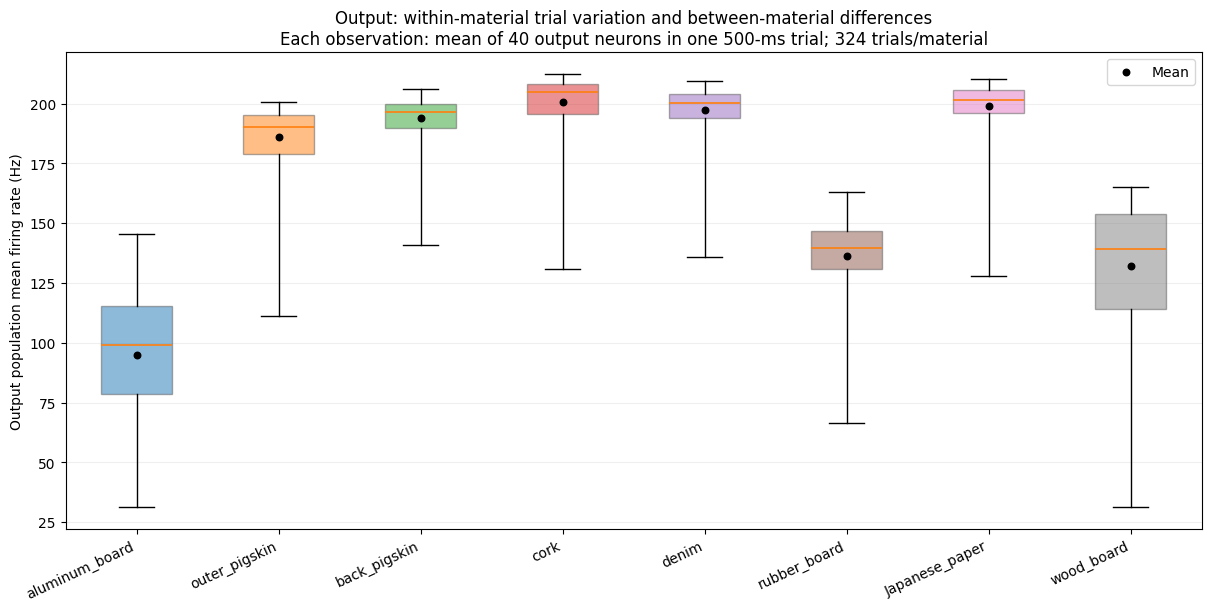

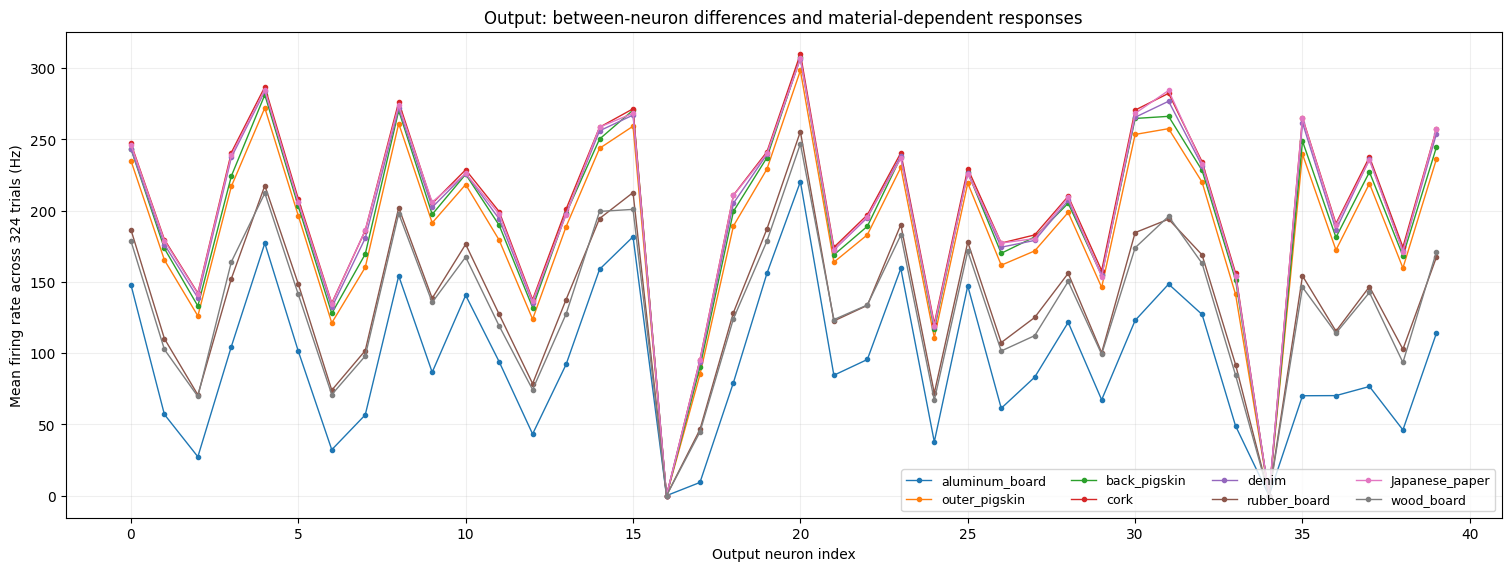

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.model_selection import StratifiedKFold
cwd=Path.cwd().resolve()
ROOT=next(p for p in [cwd,*cwd.parents] if (p/'d_tools/pca.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from d_tools.pca import fit_pca, transform_pca
from d_tools.classification import classify
from d_tools.evaluation import evaluate_classification, confusion_percentages
if 'get_ipython' in globals() and get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
SOURCE=ROOT/'g_tactile_results/calibration/output_calibration'
summary_path = SOURCE / 'output_summary.json'
if not summary_path.is_file():
    raise FileNotFoundError(f'出力層の校正結果がありません。run_calibration.py run の完了後に実行してください: {summary_path}')
settings=json.loads(summary_path.read_text(encoding='utf-8'))
if not np.isclose(float(settings['output_probability']), 0.11, rtol=0, atol=1e-12):
    raise ValueError('E→出力の結合確率11%の記録を指定してください。SOURCEを確認してください。')
MATERIALS=[r['material'] for r in settings['materials']]
POPULATIONS={'Liquid E':('liquid',80),'Output':('output',40)}
MAX_PCS=40
THREADS=4
REGULARIZATION=1e-6
states={}
for name,(folder,n) in POPULATIONS.items():
    blocks=[]
    for material in MATERIALS:
        with np.load(SOURCE/'all_materials'/material/folder/'features.npz') as data:
            np.testing.assert_array_equal(data['trial_ids'],np.arange(1,325))
            assert float(data['bin_ms'])==25.
            counts=data['counts_25ms']
            assert counts.shape==(324,100 if folder=='liquid' else n,20)
            blocks.append(counts[:,:n].astype(float)/.025)
    states[name]=np.concatenate(blocks)
labels=np.repeat(np.arange(len(MATERIALS)),324)
cv=StratifiedKFold(n_splits=10,shuffle=True,random_state=12345)
splits=list(cv.split(np.zeros(len(labels)),labels))
np.testing.assert_array_equal(np.sort(np.concatenate([te for _,te in splits])),np.arange(2592))
assert all(not np.intersect1d(tr,te).size for tr,te in splits)
print('E-to-output probability:',settings['output_probability'],'| gain:',settings['output_gain'])
print('All 2592 trials tested exactly once in stratified 10-fold CV; no standardization.')
display(pd.DataFrame([{'Population':name,'Trials':len(data),'Neurons':data.shape[1],
    'Time bins':data.shape[2],'Features':np.prod(data.shape[1:])} for name,data in states.items()]))

# --- Output firing-rate variation across trials, materials, and neurons ---
# states['Output'] は Hz 単位の（試行、出力ニューロン、時間ビン）。
# 1試行内の全出力ニューロン・全時間ビンを平均して箱ひげ図にする。
output_states_hz = states['Output']
output_n_classes = len(MATERIALS)
output_n_neurons = output_states_hz.shape[1]
output_neuron_ids = np.arange(output_n_neurons)
output_bin_ms = 25.0
output_trials_by_material = [output_states_hz[labels == i]
                             for i in range(output_n_classes)]
if any(len(block) == 0 for block in output_trials_by_material):
    raise ValueError('発火率を表示する試行がない素材があります。')
output_trial_counts = [len(block) for block in output_trials_by_material]
output_trials_label = (str(output_trial_counts[0])
                       if len(set(output_trial_counts)) == 1
                       else '/'.join(map(str, output_trial_counts)))
output_trial_population_rates_hz = [block.mean(axis=(1, 2))
                                    for block in output_trials_by_material]
output_neuron_material_rates_hz = np.stack(
    [block.mean(axis=(0, 2)) for block in output_trials_by_material])
output_rate_colors = [plt.get_cmap('tab10')(i % 10)
                      for i in range(output_n_classes)]

# 箱：25～75パーセンタイル、横線：中央値、ひげ：最小～最大、黒点：平均。
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
boxes = ax.boxplot(output_trial_population_rates_hz,
                   patch_artist=True, whis=(0, 100), showmeans=False,
                   medianprops={'color': 'tab:orange', 'linewidth': 1.2})
for box, color in zip(boxes['boxes'], output_rate_colors):
    box.set(facecolor=color, edgecolor='0.35', alpha=0.5)
ax.scatter(np.arange(1, output_n_classes + 1),
           [rates.mean() for rates in output_trial_population_rates_hz],
           color='black', s=22, zorder=3, label='Mean')
ax.set_xticks(np.arange(1, output_n_classes + 1), MATERIALS,
              rotation=25, ha='right')
ax.set(ylabel='Output population mean firing rate (Hz)',
       title=('Output: within-material trial variation and between-material differences\n'
              f'Each observation: mean of {output_n_neurons} output neurons in one '
              f'{output_states_hz.shape[-1] * output_bin_ms:g}-ms trial; '
              f'{output_trials_label} trials/material'))
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.2)
ax.legend(loc='upper right')
plt.show()

# 各素材の全試行・全時間ビンを平均し、出力ニューロンごとの応答を比較する。
fig, ax = plt.subplots(figsize=(15, 5.6), layout='constrained')
for material, rates, color in zip(MATERIALS, output_neuron_material_rates_hz,
                                  output_rate_colors):
    ax.plot(output_neuron_ids, rates, 'o-', color=color,
            markersize=3, linewidth=1, label=material)
ax.set(xlabel='Output neuron index',
       ylabel=f'Mean firing rate across {output_trials_label} trials (Hz)',
       title='Output: between-neuron differences and material-dependent responses')
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.legend(loc='lower right', ncol=4, fontsize=9)
plt.show()


In [2]:
# 全特徴とPC1〜PC40の正答率を同じ分割で計算する。結果はメモリ内。
def evaluate_population(data):
    X=data.reshape(len(data),-1)
    rows=[]
    confusion=np.zeros((8,8),dtype=np.int64)
    pca40_confusion=np.zeros((8,8),dtype=np.int64)
    with threadpool_limits(limits=THREADS):
        for fold,(tr,te) in enumerate(splits,1):
            start=time.perf_counter()
            active=np.any(X[tr]!=0,axis=0)
            train,test=X[tr][:,active],X[te][:,active]
            predicted=classify(train,labels[tr],test,regularization=REGULARIZATION)
            metrics=evaluate_classification(labels[te],predicted,labels=np.arange(8))
            confusion+=metrics['confusion_matrix']
            rows.append({'fold':fold,'representation':'Full','n_pcs':0,'accuracy':metrics['accuracy'],'correct':int((predicted==labels[te]).sum()),'n_test':len(te)})
            model=fit_pca(train,n_components=MAX_PCS)
            train_pc,test_pc=transform_pca(train,model),transform_pca(test,model)
            for k in range(1,MAX_PCS+1):
                predicted=classify(train_pc[:,:k],labels[tr],test_pc[:,:k],regularization=REGULARIZATION)
                metrics=evaluate_classification(labels[te],predicted,labels=np.arange(8))
                if k==MAX_PCS:pca40_confusion+=metrics['confusion_matrix']
                rows.append({'fold':fold,'representation':'PCA','n_pcs':k,'accuracy':metrics['accuracy'],'correct':int((predicted==labels[te]).sum()),'n_test':len(te)})
            print(f'Fold {fold}/10: Full {rows[-41]["accuracy"]:.2%}; PC40 {rows[-1]["accuracy"]:.2%}; {time.perf_counter()-start:.1f} s',flush=True)
    assert confusion.sum()==2592 and pca40_confusion.sum()==2592
    return pd.DataFrame(rows),confusion,pca40_confusion
results={};confusions={};pc40_confusions={}
for name,data in states.items():
    print(name,flush=True)
    results[name],confusions[name],pc40_confusions[name]=evaluate_population(data)
summary_rows=[]
for name,frame in results.items():
    for representation,k in [('Full',0),('PCA',1),('PCA',3),('PCA',10),('PCA',40)]:
        part=frame[(frame.representation==representation)&(frame.n_pcs==k)]
        summary_rows.append({'Population':name,'Representation':representation if k==0 else f'PC1-PC{k}',
            'Accuracy (%)':100*part.correct.sum()/part.n_test.sum(),'Correct':int(part.correct.sum()),'Total':int(part.n_test.sum())})
accuracy_summary=pd.DataFrame(summary_rows)
display(accuracy_summary.round(4))


Liquid E
Fold 1/10: Full 98.85%; PC40 98.46%; 1.2 s
Fold 2/10: Full 98.46%; PC40 98.08%; 1.0 s
Fold 3/10: Full 99.61%; PC40 98.84%; 0.9 s
Fold 4/10: Full 100.00%; PC40 98.84%; 0.9 s
Fold 5/10: Full 99.61%; PC40 98.46%; 0.9 s
Fold 6/10: Full 99.23%; PC40 99.23%; 1.0 s
Fold 7/10: Full 100.00%; PC40 100.00%; 0.9 s
Fold 8/10: Full 97.30%; PC40 97.30%; 0.9 s
Fold 9/10: Full 98.46%; PC40 97.30%; 0.9 s
Fold 10/10: Full 99.23%; PC40 99.23%; 0.8 s
Output
Fold 1/10: Full 92.69%; PC40 90.38%; 0.5 s
Fold 2/10: Full 92.69%; PC40 93.08%; 0.5 s
Fold 3/10: Full 94.21%; PC40 91.89%; 0.5 s
Fold 4/10: Full 93.82%; PC40 93.44%; 0.5 s
Fold 5/10: Full 96.53%; PC40 93.44%; 0.5 s
Fold 6/10: Full 95.37%; PC40 93.44%; 0.5 s
Fold 7/10: Full 92.66%; PC40 91.89%; 0.5 s
Fold 8/10: Full 94.98%; PC40 91.12%; 0.5 s
Fold 9/10: Full 94.98%; PC40 91.89%; 0.5 s
Fold 10/10: Full 94.21%; PC40 94.21%; 0.5 s


,Population,Representation,Accuracy (%),Correct,Total
0,Liquid E,Full,99.0741,2568,2592
1,Liquid E,PC1-PC1,39.5062,1024,2592
2,Liquid E,PC1-PC3,84.5293,2191,2592
3,Liquid E,PC1-PC10,93.8272,2432,2592
4,Liquid E,PC1-PC40,98.5725,2555,2592
5,Output,Full,94.2130,2442,2592
6,Output,PC1-PC1,37.7315,978,2592
7,Output,PC1-PC3,63.9275,1657,2592
8,Output,PC1-PC10,88.4259,2292,2592
9,Output,PC1-PC40,92.4769,2397,2592


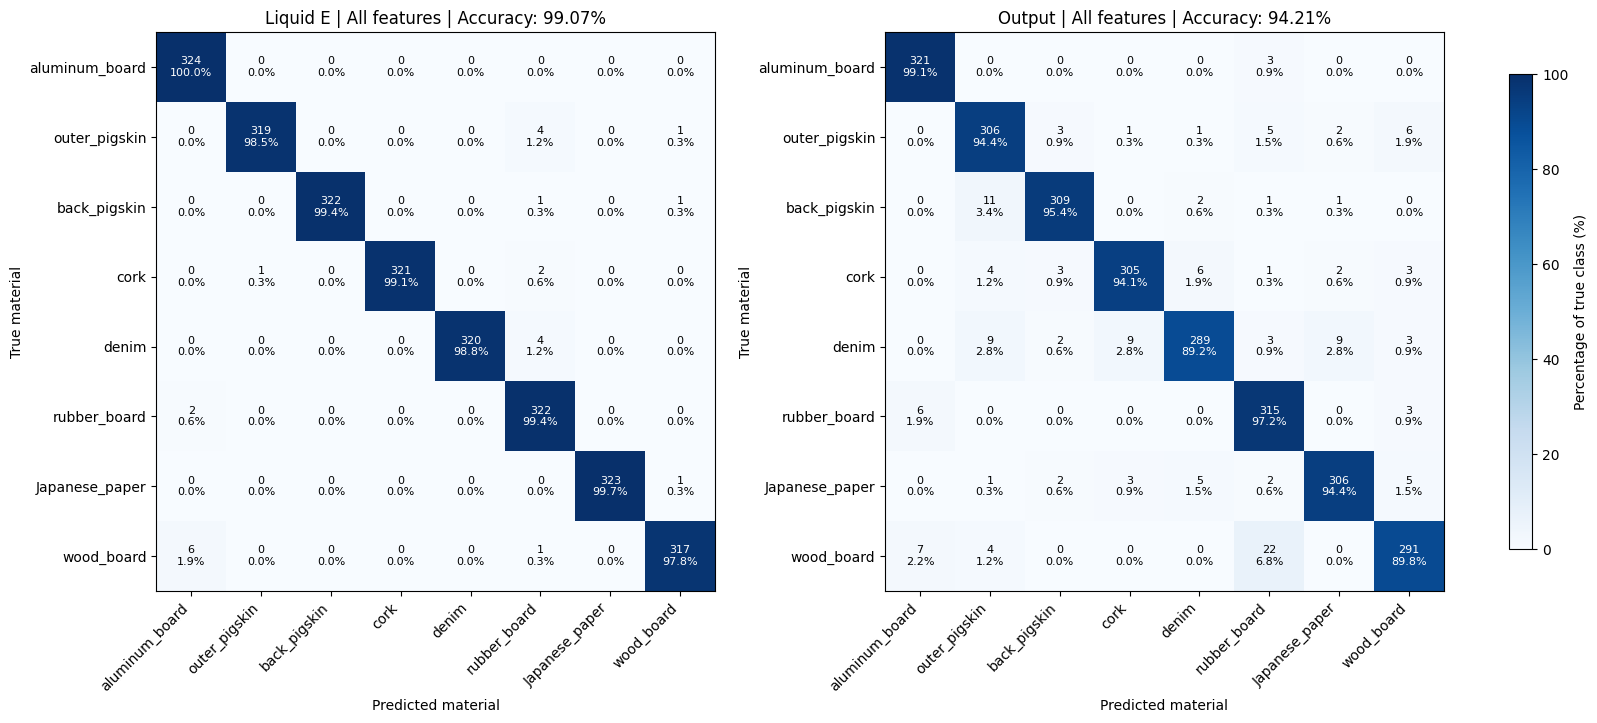

In [3]:
# 全特徴の混同行列：評価側の全2592試行を1回ずつ集計。
fig,axes=plt.subplots(1,2,figsize=(16,7),layout='constrained')
for ax,(name,cm) in zip(axes,confusions.items()):
    percent=confusion_percentages(cm)
    im=ax.imshow(percent,cmap='Blues',vmin=0,vmax=100)
    for i in range(8):
        for j in range(8):
            ax.text(j,i,f'{cm[i,j]}\n{percent[i,j]:.1f}%',ha='center',va='center',fontsize=8,color='white' if percent[i,j]>50 else 'black')
    ax.set_xticks(range(8),MATERIALS,rotation=45,ha='right')
    ax.set_yticks(range(8),MATERIALS)
    ax.set(xlabel='Predicted material',ylabel='True material',title=f'{name} | All features | Accuracy: {100*np.trace(cm)/cm.sum():.2f}%')
fig.colorbar(im,ax=axes,label='Percentage of true class (%)',shrink=.85)
plt.show()


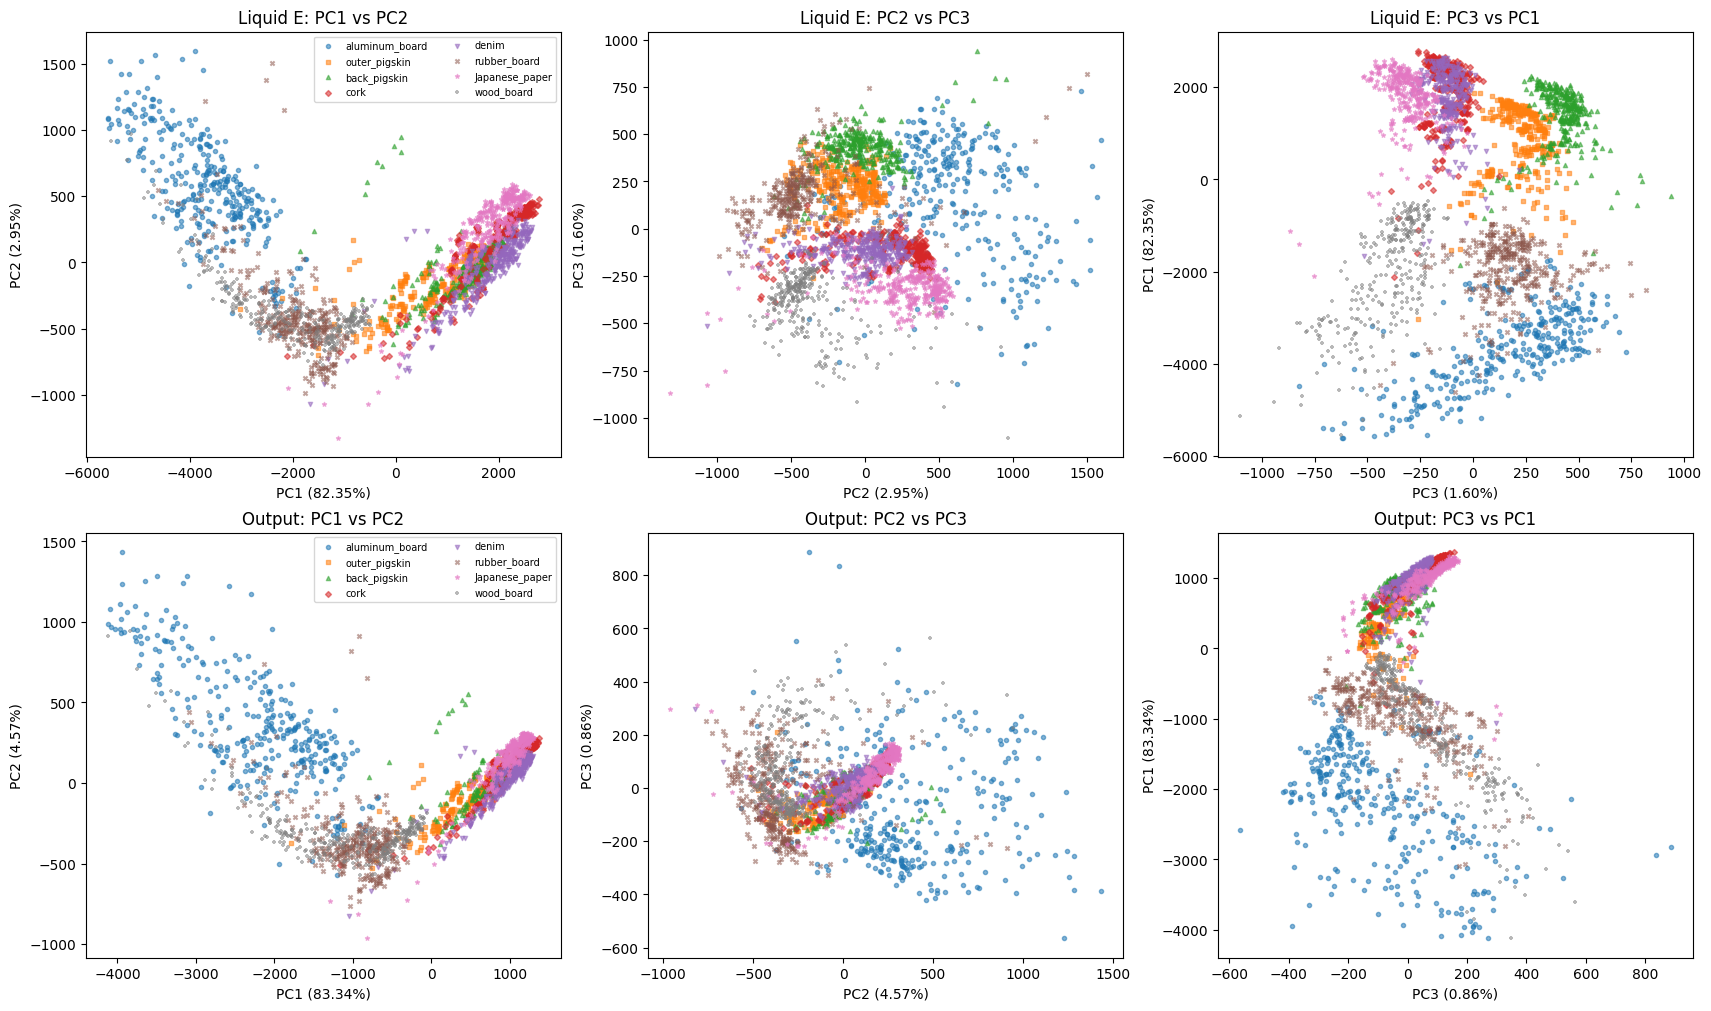

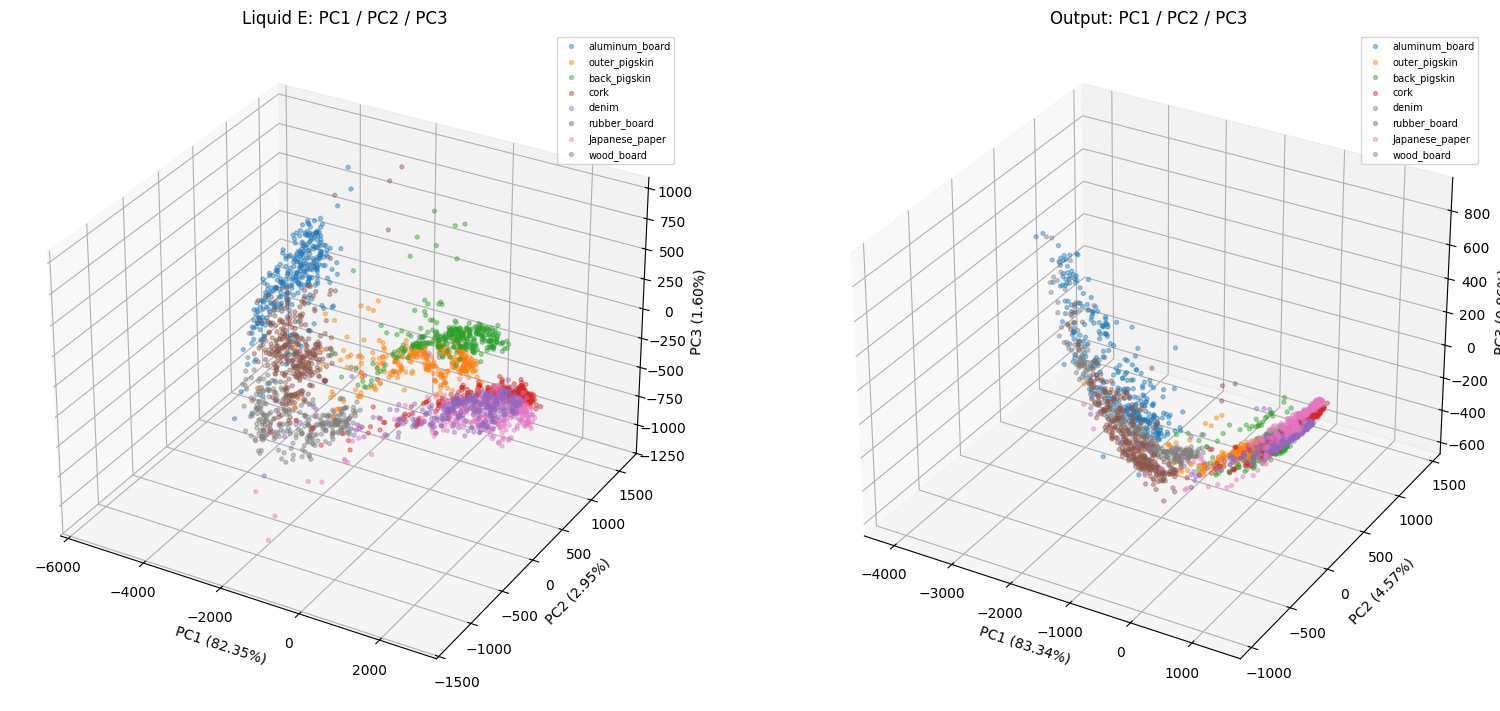

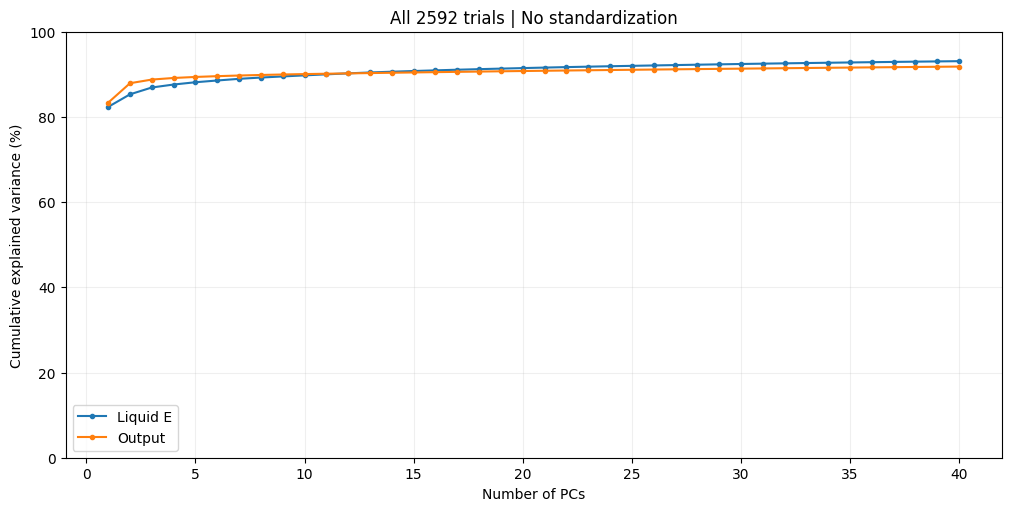

,Population,PC1 (%),PC1-PC3 (%),PC1-PC40 (%)
0,Liquid E,82.3457,86.8975,93.0760
1,Output,83.3364,88.7577,91.8064


In [4]:
# 全試行の可視化用PCA：分類評価とは別にfit。
colors=['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown','tab:pink','tab:gray']
markers=['o','s','^','D','v','x','*','+']
visual_models={};scores={};variance={}
with threadpool_limits(limits=THREADS):
    for name,data in states.items():
        model=fit_pca(data,n_components=40)
        score=transform_pca(data,model)
        peaks=np.argmax(np.abs(model.axes),axis=0)
        signs=np.sign(model.axes[peaks,np.arange(40)])
        signs[signs==0]=1
        visual_models[name]=model;scores[name]=score*signs
        variance[name]=model.explained_variance/model.total_variance*100
fig,axes=plt.subplots(2,3,figsize=(17,10),layout='constrained')
for row,name in enumerate(states):
    for col,(a,b) in enumerate([(0,1),(1,2),(2,0)]):
        ax=axes[row,col]
        for c,(material,color,marker) in enumerate(zip(MATERIALS,colors,markers)):
            mask=labels==c
            ax.scatter(scores[name][mask,a],scores[name][mask,b],s=9,alpha=.55,color=color,marker=marker,label=material)
        ax.set(xlabel=f'PC{a+1} ({variance[name][a]:.2f}%)',ylabel=f'PC{b+1} ({variance[name][b]:.2f}%)',title=f'{name}: PC{a+1} vs PC{b+1}')
        if col==0:ax.legend(fontsize=7,ncol=2)
plt.show()
fig=plt.figure(figsize=(16,7),layout='constrained')
for index,name in enumerate(states,1):
    ax=fig.add_subplot(1,2,index,projection='3d')
    for c,(material,color) in enumerate(zip(MATERIALS,colors)):
        mask=labels==c
        ax.scatter(*scores[name][mask,:3].T,s=8,alpha=.4,color=color,label=material)
    ax.set(xlabel=f'PC1 ({variance[name][0]:.2f}%)',ylabel=f'PC2 ({variance[name][1]:.2f}%)',zlabel=f'PC3 ({variance[name][2]:.2f}%)',title=f'{name}: PC1 / PC2 / PC3')
    ax.legend(fontsize=7,loc='upper right')
plt.show()
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
for name in states:ax.plot(np.arange(1,41),np.cumsum(variance[name]),'o-',ms=3,label=name)
ax.set(xlabel='Number of PCs',ylabel='Cumulative explained variance (%)',ylim=(0,100),title='All 2592 trials | No standardization')
ax.grid(alpha=.2);ax.legend();plt.show()
display(pd.DataFrame([{'Population':name,'PC1 (%)':variance[name][0], 'PC1-PC3 (%)':variance[name][:3].sum(),'PC1-PC40 (%)':variance[name].sum()} for name in states]).round(4))


40/40 output neurons | 10 selections | mean 94.21% | elapsed 2.9 s
39/40 output neurons | 10 selections | mean 94.14% | elapsed 29.9 s
38/40 output neurons | 10 selections | mean 93.91% | elapsed 56.2 s
37/40 output neurons | 10 selections | mean 93.85% | elapsed 82.1 s
36/40 output neurons | 10 selections | mean 93.75% | elapsed 107.6 s
35/40 output neurons | 10 selections | mean 93.27% | elapsed 132.6 s
34/40 output neurons | 10 selections | mean 93.14% | elapsed 157.2 s
33/40 output neurons | 10 selections | mean 92.70% | elapsed 181.4 s
32/40 output neurons | 10 selections | mean 92.39% | elapsed 205.3 s
31/40 output neurons | 10 selections | mean 91.91% | elapsed 228.6 s
30/40 output neurons | 10 selections | mean 91.70% | elapsed 250.9 s
29/40 output neurons | 10 selections | mean 91.39% | elapsed 270.5 s
28/40 output neurons | 10 selections | mean 90.98% | elapsed 288.2 s
27/40 output neurons | 10 selections | mean 90.62% | elapsed 305.3 s
26/40 output neurons | 10 selections | 

,Output neurons,Mean accuracy (%),SD (percentage points),Min accuracy (%),Max accuracy (%),Selections
0,40,94.213,0.000,94.213,94.213,10
1,39,94.144,0.149,93.827,94.329,10
2,38,93.912,0.257,93.519,94.290,10
3,37,93.854,0.247,93.557,94.483,10
4,36,93.746,0.399,93.210,94.367,10
5,35,93.272,0.270,92.708,93.711,10
6,34,93.137,0.326,92.670,93.634,10
7,33,92.704,0.323,92.245,93.210,10
8,32,92.388,0.420,91.782,92.940,10
9,31,91.910,0.558,91.242,92.940,10


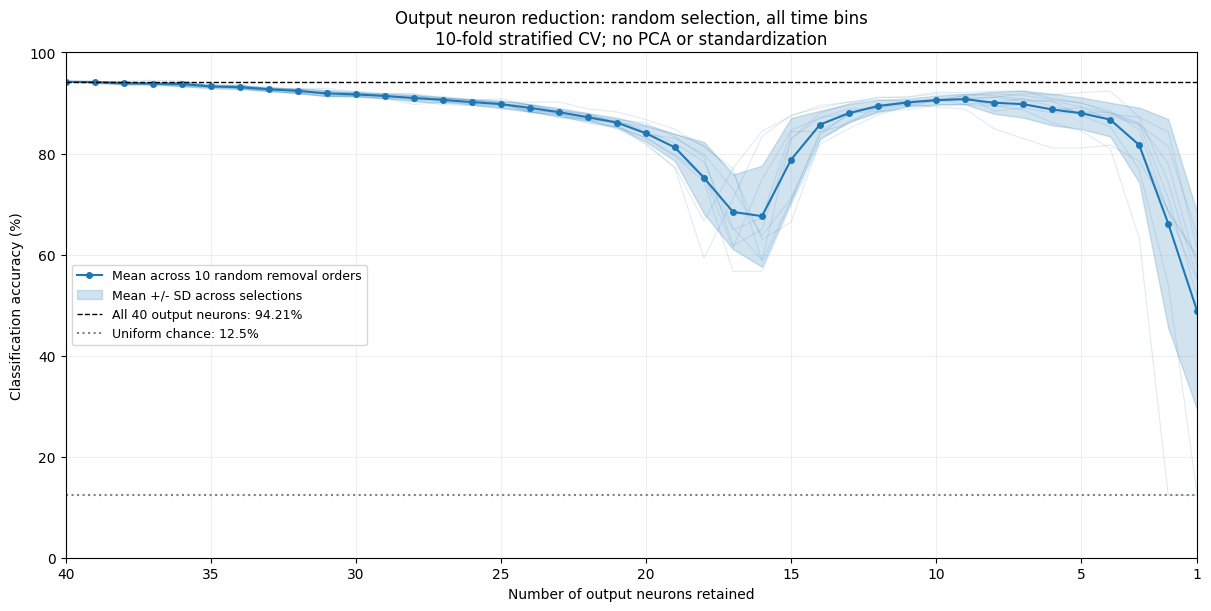

In [5]:
# --- Random output-neuron reduction: 10 removal orders, all time bins ---
# 40→1個へ1個ずつ減らす。ランダムな除去順を10通り作り、各個数で10回評価する。
# 同じ除去順では、少ない個数のニューロン集合は直前の集合の部分集合になる。
# 各集合で既存の層別10分割を使う。全時間ビンを使用し、PCA・標準化は行わない。
# 乱数はニューロン選択専用。学習・評価の試行分割は変えず、結果は外部保存しない。
if 'states' not in globals() or 'splits' not in globals():
    raise RuntimeError('最初のコードセルで状態と試行分割を読み込んでください。')

NEURON_REDUCTION_REPEATS = 10
NEURON_REDUCTION_SEED = 12345
reduction_output_states = np.asarray(states['Output'])
reduction_n_neurons = reduction_output_states.shape[1]
reduction_rng = np.random.default_rng(NEURON_REDUCTION_SEED)
reduction_orders = np.stack([reduction_rng.permutation(reduction_n_neurons)
                             for _ in range(NEURON_REDUCTION_REPEATS)])
reduction_counts = np.arange(reduction_n_neurons, 0, -1)
# 各試行が評価側に1回だけ入ることを確認し、正解数/全評価試行数を正答率とする。
np.testing.assert_array_equal(np.sort(np.concatenate([te for _, te in splits])),
                              np.arange(len(labels)))
if any(np.intersect1d(tr, te).size for tr, te in splits):
    raise ValueError('学習試行と評価試行が重複しています。')


def evaluate_output_neuron_subset(neuron_ids):
    subset = reduction_output_states[:, neuron_ids, :]
    features = subset.reshape(len(subset), -1)
    correct, tested = 0, 0
    for train_ids, test_ids in splits:
        train_x = features[train_ids]
        # 無活動特徴の判定も学習側だけで行う。
        active = np.any(train_x != 0, axis=0)
        if active.any():
            predicted = classify(train_x[:, active], labels[train_ids],
                                 features[test_ids][:, active],
                                 regularization=REGULARIZATION)
        else:
            # 選んだニューロンが全て無活動なら、学習側の最多クラスを予測する。
            classes, counts = np.unique(labels[train_ids], return_counts=True)
            predicted = np.full(len(test_ids), classes[np.argmax(counts)])
        correct += int(np.count_nonzero(predicted == labels[test_ids]))
        tested += len(test_ids)
    return correct, tested


reduction_rows = []
reduction_cache = {}  # 全40個など、同じ集合の評価は1回だけ計算して再利用する。
reduction_start = time.perf_counter()
with threadpool_limits(limits=THREADS):
    for n_neurons in reduction_counts:
        count_accuracies = []
        for repeat, order in enumerate(reduction_orders, 1):
            neuron_ids = tuple(sorted(map(int, order[:n_neurons])))
            if neuron_ids not in reduction_cache:
                reduction_cache[neuron_ids] = evaluate_output_neuron_subset(neuron_ids)
            correct, tested = reduction_cache[neuron_ids]
            accuracy = correct / tested
            count_accuracies.append(accuracy)
            reduction_rows.append({'n_neurons': int(n_neurons), 'repeat': repeat,
                                   'neuron_ids': neuron_ids, 'correct': correct,
                                   'n_test': tested, 'accuracy': accuracy})
        print(f'{n_neurons:2d}/{reduction_n_neurons} output neurons | '
              f'{NEURON_REDUCTION_REPEATS} selections | '
              f'mean {np.mean(count_accuracies):.2%} | '
              f'elapsed {time.perf_counter()-reduction_start:.1f} s', flush=True)

output_neuron_reduction_results = pd.DataFrame(reduction_rows)
output_neuron_reduction_summary = (
    output_neuron_reduction_results.groupby('n_neurons', sort=False)
    .agg(mean_accuracy=('accuracy', 'mean'), sd_accuracy=('accuracy', 'std'),
         min_accuracy=('accuracy', 'min'), max_accuracy=('accuracy', 'max'),
         selections=('accuracy', 'size')).reset_index())
reduction_display = output_neuron_reduction_summary.rename(columns={
    'n_neurons': 'Output neurons', 'mean_accuracy': 'Mean accuracy (%)',
    'sd_accuracy': 'SD (percentage points)', 'min_accuracy': 'Min accuracy (%)',
    'max_accuracy': 'Max accuracy (%)', 'selections': 'Selections'}).copy()
for column in ['Mean accuracy (%)', 'SD (percentage points)',
               'Min accuracy (%)', 'Max accuracy (%)']:
    reduction_display[column] *= 100
print('SD is across the 10 neuron selections, not across the CV folds. '
      'All-neuron selections are identical.')
display(reduction_display.round(3))

fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
for repeat, part in output_neuron_reduction_results.groupby('repeat'):
    ax.plot(part['n_neurons'], part['accuracy'] * 100,
            color='tab:blue', alpha=0.14, linewidth=0.8)
x = output_neuron_reduction_summary['n_neurons'].to_numpy()
y = output_neuron_reduction_summary['mean_accuracy'].to_numpy() * 100
sd = output_neuron_reduction_summary['sd_accuracy'].to_numpy() * 100
ax.plot(x, y, 'o-', color='tab:blue', markersize=4,
        label=f'Mean across {NEURON_REDUCTION_REPEATS} random removal orders')
ax.fill_between(x, np.maximum(0, y-sd), np.minimum(100, y+sd),
                color='tab:blue', alpha=0.2, label='Mean +/- SD across selections')
ax.axhline(y[0], color='black', linestyle='--', linewidth=1,
           label=f'All {reduction_n_neurons} output neurons: {y[0]:.2f}%')
ax.axhline(100 / len(np.unique(labels)), color='gray', linestyle=':',
           label=f'Uniform chance: {100 / len(np.unique(labels)):g}%')
ax.set(xlabel='Number of output neurons retained', ylabel='Classification accuracy (%)',
       title=('Output neuron reduction: random selection, all time bins\n'
              f'{len(splits)}-fold stratified CV; no PCA or standardization'),
       ylim=(0, 100))
if reduction_n_neurons > 1:
    ax.set_xlim(reduction_n_neurons, 1)  # 左から右へ40→1個。
ax.set_xticks(sorted(set([1, reduction_n_neurons] +
                        list(range(5, reduction_n_neurons, 5)))))
ax.grid(alpha=0.2)
ax.legend(loc='best', fontsize=9)
plt.show()
